In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt

Loading Images from Drive to Dataset Folder

In [3]:
IMAGE_SIZE=256
BATCH_SIZE=32
CHANNEL=3
EPOCHS=50

In [4]:
df=tf.keras.preprocessing.image_dataset_from_directory(
    "/content/drive/MyDrive/PlantDataset",
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    image_size=(IMAGE_SIZE, IMAGE_SIZE),
    shuffle=True,
)

Found 2134 files belonging to 3 classes.


In [5]:
df_class_name = df.class_names
print(df_class_name)

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [6]:
len(df)

67

Visualizing 12 images from each random batch

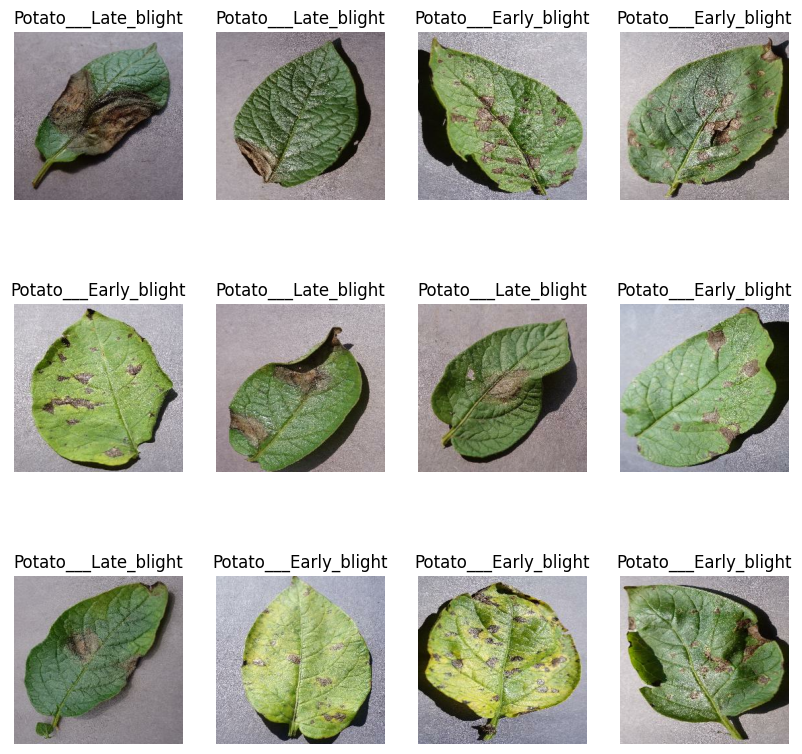

In [7]:
plt.figure(figsize=(10,10))
for image_batch, label_batch in df.take(1):
  for i in range(12):
    ax=plt.subplot(3,4,i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8")) #plt.imshow() is a matplotlib functionality which is used to visualize image
    plt.axis("off")
    plt.title(df_class_name[label_batch[i]])

In [8]:
len(df)

67

Train Test Split for Images from Dataset

```
# This is formatted as code
```



In [9]:
def train_test_split(df, train_split=0.8, test_split=0.1, val_split=0.1, shuffle=True, shuffle_size=10000):
  ds_size = len(df)
  if shuffle:
    df = df.shuffle(shuffle_size,seed=42)
  train_size = int(ds_size*train_split)
  val_size = int(ds_size*val_split)
  train_ds = df.take(train_size)
  val_ds = df.skip(train_size).take(val_size)
  test_ds = df.skip(train_size).skip(val_size)
  return train_ds, test_ds, val_ds

In [10]:
len(df)

67

In [11]:
train_ds, test_ds, val_ds = train_test_split(df)
print(len(train_ds))
print(len(test_ds))
print(len(val_ds))

53
8
6


Performance Optimization using Prefetch and Cache

In [12]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

Image Preprocessing: Step-1: Image Scaling and Resizing

In [13]:
resize_and_rescale=tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    layers.Rescaling(1.0/255)
])

Image Preprocessing: Step-2: Image Augmentation

In [14]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("Horizontal and Vertical"),
    layers.RandomRotation(0.2)
])

Convolutional Model Building

In [15]:
input_shape = (BATCH_SIZE,IMAGE_SIZE,IMAGE_SIZE,CHANNEL)
n_layers = 3
model = models.Sequential([
    resize_and_rescale,
    data_augmentation,
    layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_layers, activation='softmax')
])
model.build(input_shape=input_shape)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (32, 256, 256, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 254, 254, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 127, 127, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 125, 125, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 62, 62, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 60, 60, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 30, 30, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 28, 28, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 14, 14, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 12, 12, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 6, 6, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 4, 4, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 2, 2, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 256)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 64)               │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,747 (717.76 KB)

 Trainable params: 183,747 (717.76 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1,
    validation_data=val_ds
)

Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 157s 156ms/step - accuracy: 0.5219 - loss: 0.8955 - val_accuracy: 0.6927 - val_loss: 0.8304
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.7295 - loss: 0.6599 - val_accuracy: 0.7917 - val_loss: 0.4830
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8405 - loss: 0.4009 - val_accuracy: 0.9115 - val_loss: 0.2444
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8808 - loss: 0.3002 - val_accuracy: 0.8906 - val_loss: 0.2681
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.8695 - loss: 0.3265 - val_accuracy: 0.8490 - val_loss: 0.3614
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.8796 - loss: 0.3060 - val_accuracy: 0.8750 - val_loss: 0.2699
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9033 - loss: 0.2271 - val_accuracy: 0.9219 - val_loss: 0.2125
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.9359 - loss: 0.1747 - val_accuracy: 0.9531 

In [21]:
scores=model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9959 - loss: 0.0215


In [22]:
scores

[0.021463995799422264, 0.9959349632263184]

In [24]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 53}

In [25]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [26]:
history.history['accuracy']

[0.5219454169273376,
 0.7295373678207397,
 0.8404507637023926,
 0.8807829022407532,
 0.8695136308670044,
 0.8795966506004333,
 0.9033214449882507,
 0.935943067073822,
 0.9371293187141418,
 0.9537366628646851,
 0.9549229145050049,
 0.9572953581809998,
 0.9661921858787537,
 0.9602609872817993,
 0.9733096361160278,
 0.9389086365699768,
 0.9466192126274109,
 0.9744958281517029,
 0.972123384475708,
 0.9827995300292969,
 0.9792408347129822,
 0.9881376028060913,
 0.9851720333099365,
 0.9750889539718628,
 0.981613278388977,
 0.9875444769859314,
 0.9833926558494568,
 0.982206404209137,
 0.9827995300292969,
 0.9839857816696167,
 0.989916980266571,
 0.9792408347129822,
 0.981613278388977,
 0.9922894239425659,
 0.9869513511657715,
 0.9810201525688171,
 0.9839857816696167,
 0.9857650995254517,
 0.9934756755828857,
 0.981613278388977,
 0.9934756755828857,
 0.9845789074897766,
 0.9887307286262512,
 0.9940688014030457,
 0.9946619272232056,
 0.9946619272232056,
 0.9792408347129822,
 0.9875444769859314,

In [27]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

Text(0.5, 1.0, 'Training and Validation accuracy')

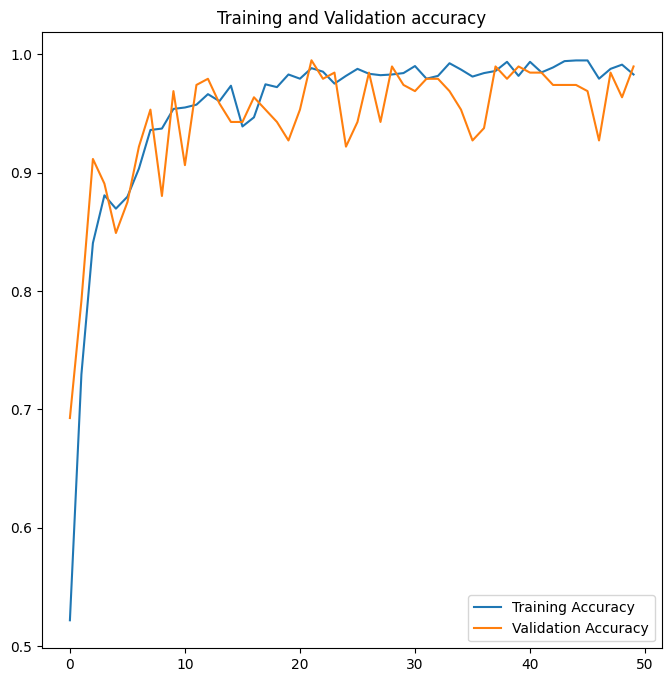

In [30]:
plt.figure(figsize=(8,8))
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS),val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation accuracy')

First image to predict:
First image actual label: Potato___Early_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
First image predicted label: Potato___Early_blight


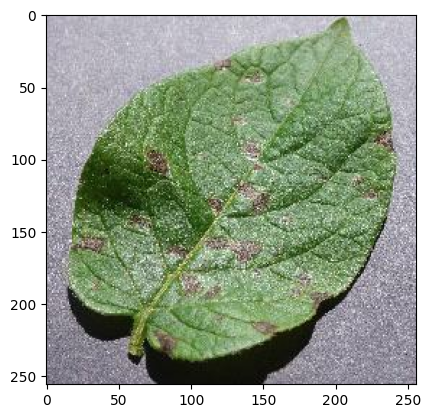

In [36]:
import numpy as np
for image_batch, labels_batch in test_ds.take(1):
  first_image = image_batch[0].numpy().astype('uint8')
  first_label = labels_batch[0]
  print("First image to predict:")
  plt.imshow(first_image)
  print('First image actual label:',df.class_names[first_label])

  #We will now get predicted class
  batch_prediction = model.predict(image_batch)
  print('First image predicted label:',df.class_names[np.argmax(batch_prediction[0])])

In [39]:
def predict(model, img):
  img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
  img_array = tf.expand_dims(img_array,0)

  predictions = model.predict(img_array)

  predicted_class = df.class_names[np.argmax(predictions[0])]
  confidence = round(100*(np.max(predictions[0])),2)
  return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


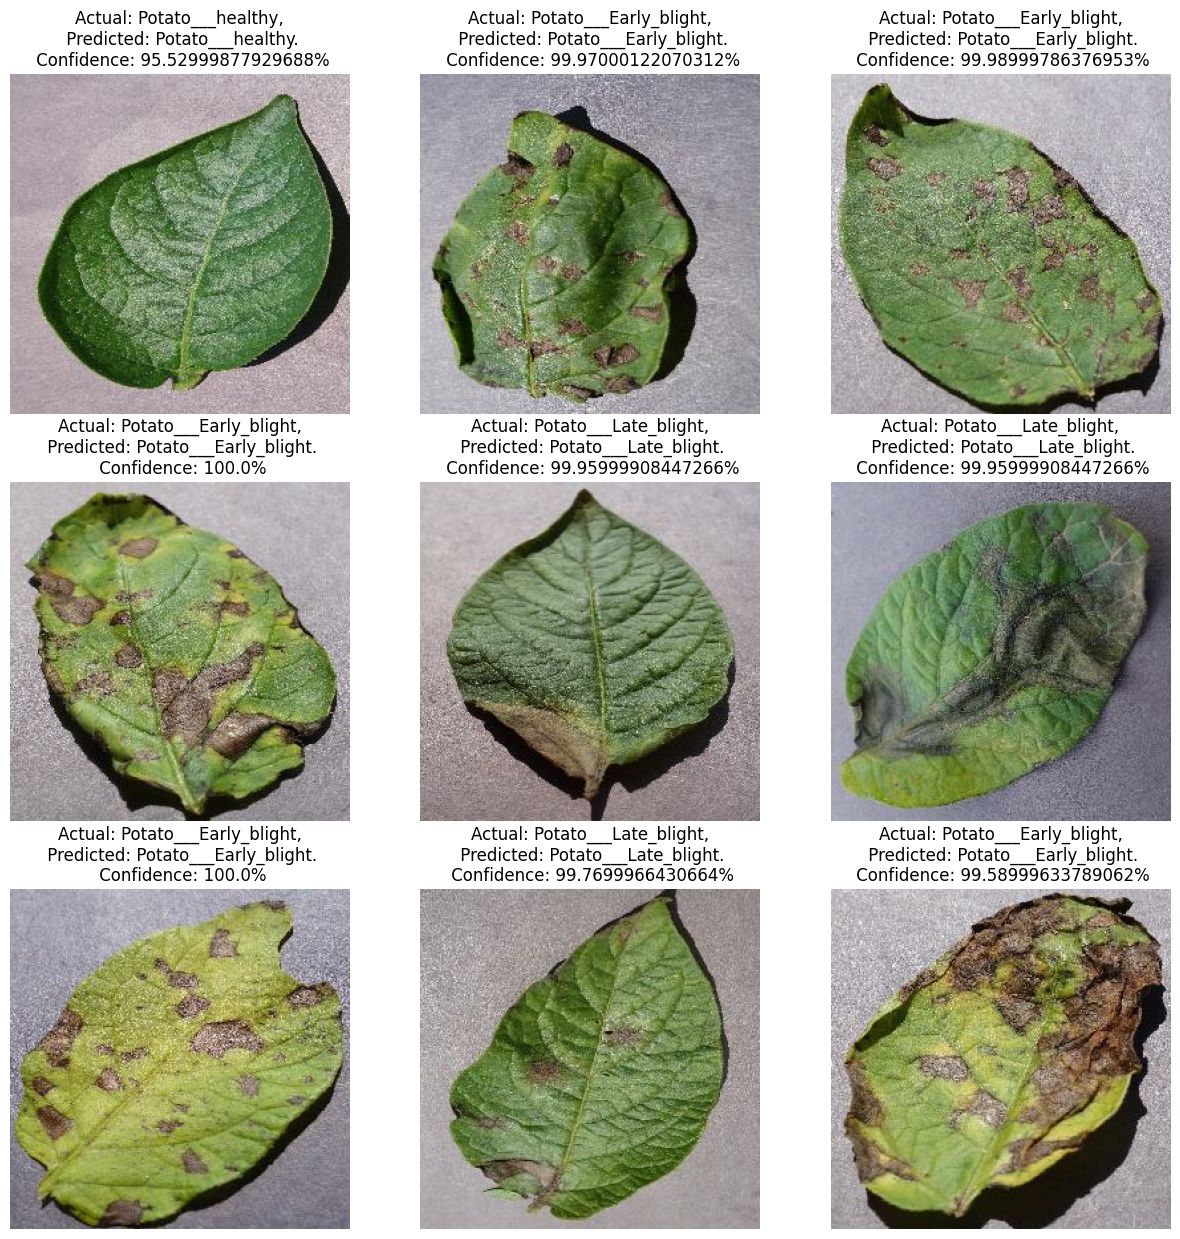

In [41]:
plt.figure(figsize=(15,15))
for images, labels in test_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3,3,i+1)
    plt.imshow(images[i].numpy().astype('uint8'))

    predicted_class, confidence = predict(model,images[i].numpy())
    actual_class = df.class_names[labels[i]]
    plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
    plt.axis("off")